# Assignment 1

In [98]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import binom 

## Question 3

In [ ]:
def est_1(vals,mu):
    '''
    Estimator 1. 

    Parameters:
    ----------
    vals : input values x_i 
    mu : expectation value
    '''
    return np.sum((vals-mu)**2)/np.shape(vals)[0]

def est_2(vals):
    '''
    Estimator 2. 

    Parameters:
    ----------
    vals : input values x_i 
    '''
    xbar = np.mean(vals)
    return np.sum((vals-xbar)**2)/np.shape(vals)[0]

def est_3(vals):
    '''
    Estimator 3. 

    Parameters:
    ----------
    vals : input values x_i 
    '''
    xbar = np.mean(vals)
    return np.sum((vals-xbar)**2)/(np.shape(vals)[0]-1)

In [90]:
# draw 10 numbers from gaussian distribution 
mu = 2 
sigma = 1
nums = np.random.normal(mu,sigma,(10,))
nums

array([2.8125311 , 2.72157498, 1.43183061, 1.70366828, 3.45478352,
       1.12793118, 1.06937779, 1.80203546, 1.1716036 , 0.71892151])

In [91]:
# print the output from the three estimators 
print(est_1(nums,mu),est_2(nums),est_3(nums))

0.7701055649873388 0.7306738530962105 0.8118598367735672


In [93]:
# repeat this for M trials
M = 100
est_1_vals = []
est_2_vals = []
est_3_vals = []
for m in range(M):
    nums = np.random.normal(mu,sigma,(10,))
    est_1_vals.append(est_1(nums,mu))
    est_2_vals.append(est_2(nums))
    est_3_vals.append(est_3(nums))

print(np.mean(est_1_vals),np.mean(est_2_vals),np.mean(est_3_vals))

0.9945862153605423 0.8921062044346222 0.9912291160384692


Repeating this for 100 trials makes it clear that the second estimator is definitely biased small. 

## Question 4

In [95]:
def neg_bin_dist(N,m,p):
    '''
    Negative binomial ditribution.

    Parameters:
    ----------
    N : number of trials 
    m : number of successes 
    p : probability of success per trial
    '''
    return binom(N-1,m-1) * p**m * (1-p)**(N-m)

In [221]:
# plot values of N between 1 and 50
N = np.linspace(1,50,50)

Text(0.5, -0.05, 'Distribution for the number of trials $N$ required to obtain $m=10$ heads in a fair coin toss ($p$ = 0.5)')

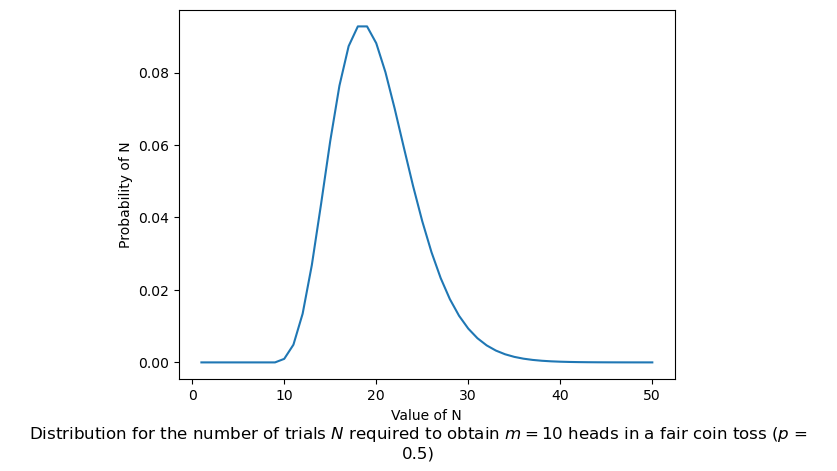

In [229]:
fig,ax = plt.subplots(1,1)
ax.plot(N,neg_bin_dist(N,10,0.5))

ax.set_xlabel('Value of N')
ax.set_ylabel('Probability of N')

caption = 'Distribution for the number of trials $N$ required to obtain $m=10$ heads in a fair coin toss ($p$ = 0.5)'
plt.figtext(0.5, -0.05, caption, wrap=True, horizontalalignment='center', fontsize=12)


This is not symmetric about the mode. 

## Question 5

In [119]:
def post_density(x,y):
    '''
    '''
    A1 = 3.93161
    A2 = 3.61472
    x1 = 0.5
    x2 = 0.65
    y1 = 0.5
    y2 = 0.75
    sig1 = 0.2
    sig2 = 0.04
    return A1 * np.exp(-(((x-x1)**2+(y-y1)**2)/(2*sig1**2))) + A2 * np.exp(-(((x-x2)**2+(y-y2)**2)/(2*sig2**2)))

In [166]:
# make x and y arrays
x = np.linspace(0,1,100)
y = np.linspace(0,1,100)

In [165]:
xplt = np.meshgrid(x,y)[0]
yplt = np.meshgrid(x,y)[1]

### Part a)

Text(0.5, -0.05, 'Contour plot of posterior density.')

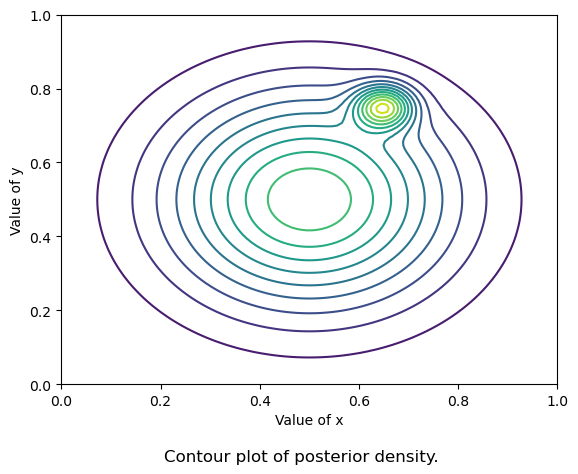

In [230]:
fig,ax = plt.subplots(1,1)
ax.contour(xplt, yplt, post_density(xplt,yplt),levels=15)
ax.set_xlabel('Value of x')
ax.set_ylabel('Value of y')

caption = 'Contour plot of posterior density.'
plt.figtext(0.5, -0.05, caption, wrap=True, horizontalalignment='center', fontsize=12)

### Part b)

Text(0.5, -0.05, '3D plot of posterior density.')

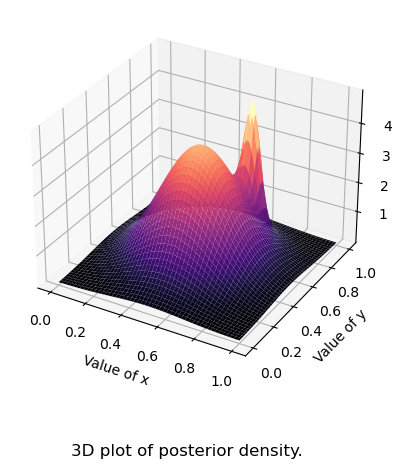

In [232]:
fig, ax = plt.subplots(subplot_kw=dict(projection='3d'))
ax.plot_surface(xplt, yplt, post_density(xplt,yplt),cmap='magma')
ax.set_xlabel('Value of x')
ax.set_ylabel('Value of y')

caption = '3D plot of posterior density.'
plt.figtext(0.5, -0.05, caption, wrap=True, horizontalalignment='center', fontsize=12)

### Part c)

In [161]:
ints = np.linspace(0,1,1001)[:-1]
dx = np.diff(ints)[0]
dy = dx

Text(0.5, -0.05, '$x$ and $y$ marginal probability distributions for posterior density.')

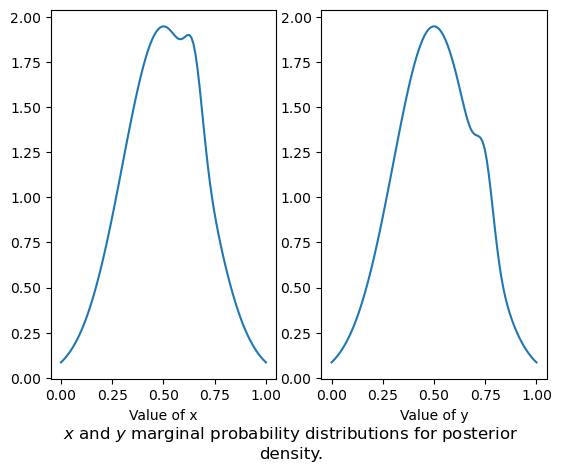

In [234]:
fig,axs = plt.subplots(1,2)

xpltint = np.meshgrid(x,ints)[0]
ypltint = np.meshgrid(x,ints)[1]

axs[0].plot(x,np.sum(post_density(xpltint,ypltint).T,axis=1)*dy)
axs[0].set_xlabel('Value of x')

xpltint = np.meshgrid(ints,y)[0]
ypltint = np.meshgrid(ints,y)[1]

axs[1].plot(y,np.sum(post_density(xpltint,ypltint),axis=1)*dx)
axs[1].set_xlabel('Value of y')

caption = '$x$ and $y$ marginal probability distributions for posterior density.'
plt.figtext(0.5, -0.05, caption, wrap=True, horizontalalignment='center', fontsize=12)

In [172]:
# check to make sure it integrates to 1 
xpltint = np.meshgrid(ints,ints)[0]
ypltint = np.meshgrid(ints,ints)[1]
np.sum(np.sum(post_density(xpltint,ypltint).T,axis=1)*dy)*dx

1.0000689356551917

### Part d)

Text(0.5, -0.05, '$x$ and $y$ projected probability distributions for posterior density.')

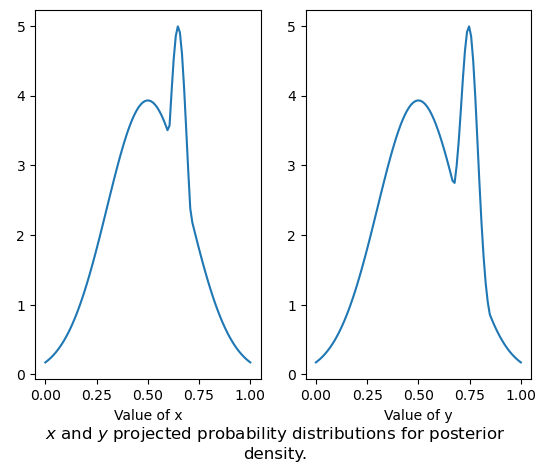

In [235]:
fig,axs = plt.subplots(1,2)

axs[0].plot(x,np.max(post_density(xplt,yplt).T,axis=1))
axs[0].set_xlabel('Value of x')

axs[1].plot(y,np.max(post_density(xplt,yplt),axis=1))
axs[1].set_xlabel('Value of y')

caption = '$x$ and $y$ projected probability distributions for posterior density.'
plt.figtext(0.5, -0.05, caption, wrap=True, horizontalalignment='center', fontsize=12)

### Part e)

Text(0.5, -0.05, 'Comparison of $x$ and $y$ marginal and projected probability distributions.')

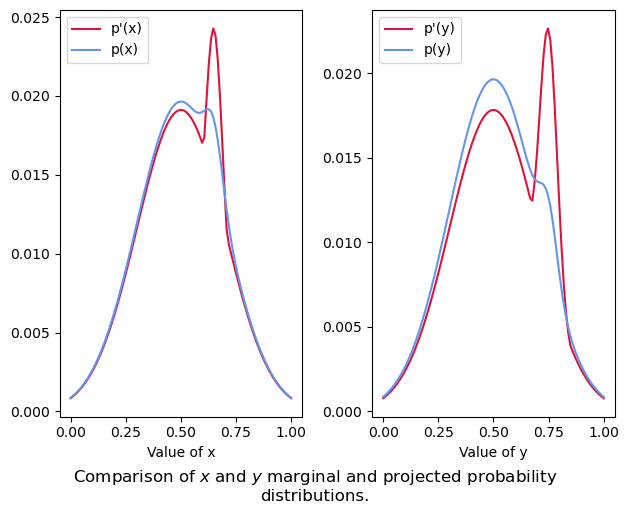

In [236]:
fig,axs = plt.subplots(1,2)

xpltint = np.meshgrid(x,ints)[0]
ypltint = np.meshgrid(x,ints)[1]
axs[0].plot(x,np.max(post_density(xplt,yplt).T,axis=1)/np.sum(np.max(post_density(xplt,yplt).T,axis=1)),label='p\'(x)',color='crimson')
axs[0].plot(x,np.sum(post_density(xpltint,ypltint).T,axis=1)*dx/np.sum(np.sum(post_density(xpltint,ypltint).T,axis=1)*dx),label='p(x)',color='cornflowerblue')
axs[0].set_xlabel('Value of x')
axs[0].legend()

xpltint = np.meshgrid(ints,y)[0]
ypltint = np.meshgrid(ints,y)[1]
axs[1].plot(y,np.max(post_density(xplt,yplt),axis=1)/np.sum(np.max(post_density(xplt,yplt),axis=1)),label='p\'(y)',color='crimson')
axs[1].plot(y,np.sum(post_density(xpltint,ypltint),axis=1)*dx/np.sum(np.sum(post_density(xpltint,ypltint),axis=1)*dy),label='p(y)',color='cornflowerblue')
axs[1].set_xlabel('Value of y')
axs[1].legend()

fig.tight_layout()

caption = 'Comparison of $x$ and $y$ marginal and projected probability distributions.'
plt.figtext(0.5, -0.05, caption, wrap=True, horizontalalignment='center', fontsize=12)